# Nearest neighbours: a self-study investigation

**Question:** Are the nearest-neighbour distances unusually short under a homogeneous random point process?

Read the [NNA section](../chapter_4/sec_04-03-Nearest-Neighbor-Analysis.md), then run this notebook from top to bottom. The default data are synthetic: no course data, Google Drive account or helper module is needed. The [full point-pattern lab](lab-05-point-pattern.ipynb) provides the HDB application and other methods.

You will calculate the observed distance and ratio, run a finite-window Monte Carlo test, and compare it with the analytical Clark–Evans approximation. Before running the results, predict what changing the study window will do.

## 1. Setup

Use Python 3 with NumPy, SciPy and Matplotlib. If needed, run `%pip install numpy scipy matplotlib` in a separate cell and restart the kernel. On Colab, upload this notebook and run the cells; no Drive mount is required.

All coordinates below are **metres in a synthetic planar window**, not longitude and latitude. For real data, first project to a suitable coordinate reference system, then supply matching window bounds in the same units.

In [1]:
from pathlib import Path
import numpy as np
from scipy.spatial import KDTree
from scipy.stats import norm
import matplotlib.pyplot as plt

# EDIT HERE: choose the question before inspecting the p-value.
PATTERN = "clustered"   # "clustered", "csr", or "regular"
ALTERNATIVE = "less"    # "less" = clustering; "greater" = dispersion; "two-sided"
WINDOW = (0.0, 0.0, 1000.0, 1000.0)  # xmin, ymin, xmax, ymax, metres
N_POINTS = 100
N_SIMULATIONS = 999
SEED = 7
DATA_CSV = None          # optional path to a CSV with numeric columns x and y


## 2. Generate or load observations

The clustered example groups events around two centres. The CSR example samples independent uniform locations. The regular example puts events on a square grid. These are teaching examples, not geographical observations.

For your own CSV, retain `x,y` as the header and set `DATA_CSV` and `WINDOW` above. Each row represents one event. Repeated coordinates are retained: decide whether your question concerns repeated events or distinct locations. The fixed rectangle is an analytical choice; do not infer it from each simulated pattern's bounding box.

In [2]:
def validate_window(window):
    bounds = np.asarray(window, dtype=float)
    if bounds.shape != (4,) or not np.isfinite(bounds).all():
        raise ValueError("WINDOW must contain four finite bounds.")
    lower, upper = bounds[:2], bounds[2:]
    if np.any(upper <= lower):
        raise ValueError("Each maximum bound must exceed its minimum.")
    return lower, upper


def validate_points(points, window):
    points = np.asarray(points, dtype=float)
    lower, upper = validate_window(window)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) < 2:
        raise ValueError("Supply at least two points with x and y coordinates.")
    if not np.isfinite(points).all():
        raise ValueError("Point coordinates must be finite.")
    if np.any(points < lower) or np.any(points > upper):
        raise ValueError("Every point must lie inside the stated window.")
    return points


def make_pattern(kind, n, window, rng):
    lower, upper = validate_window(window)
    if kind == "csr":
        return rng.uniform(lower, upper, size=(n, 2))
    if kind == "regular":
        side = int(np.sqrt(n))
        if side * side != n:
            raise ValueError("For the regular grid, use a square point count, e.g. 100.")
        x = np.linspace(lower[0], upper[0], 2 * side + 1)[1::2]
        y = np.linspace(lower[1], upper[1], 2 * side + 1)[1::2]
        return np.column_stack([v.ravel() for v in np.meshgrid(x, y)])
    if kind == "clustered":
        centres = lower + (upper - lower) * np.array([[0.3, 0.35], [0.7, 0.65]])
        points = []
        while len(points) < n:
            centre = centres[rng.integers(2)]
            point = rng.normal(centre, (upper - lower) * 0.055)
            if np.all(point >= lower) and np.all(point <= upper):
                points.append(point)
        return np.asarray(points)
    raise ValueError("PATTERN must be clustered, csr or regular.")


# Separate streams keep observations fixed when the simulation count changes.
observed_seed, simulation_seed = np.random.SeedSequence(SEED).spawn(2)
observed_rng = np.random.default_rng(observed_seed)
if DATA_CSV is None:
    points = make_pattern(PATTERN, N_POINTS, WINDOW, observed_rng)
else:
    table = np.atleast_1d(np.genfromtxt(Path(DATA_CSV), delimiter=",", names=True))
    if not {"x", "y"}.issubset(table.dtype.names or ()):
        raise ValueError("The CSV must have columns named x and y.")
    points = np.column_stack((table["x"], table["y"]))
points = validate_points(points, WINDOW)
print(f"Events: {len(points)}; distinct coordinates: {len(np.unique(points, axis=0))}")


Events: 100; distinct coordinates: 100


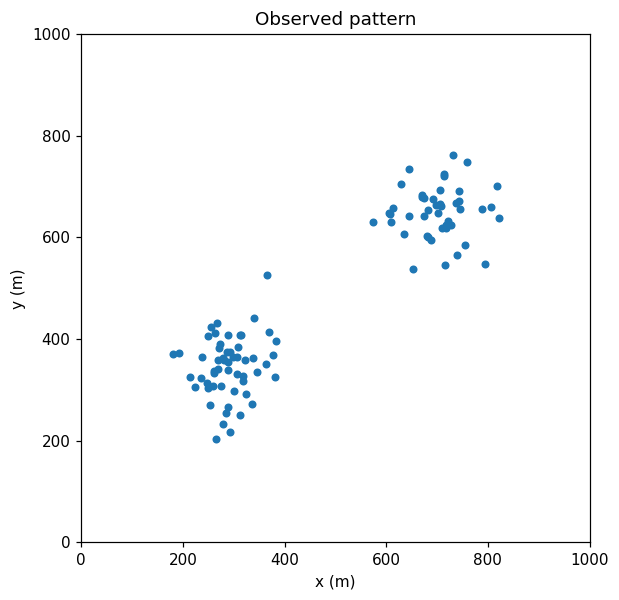

In [3]:
lower, upper = validate_window(WINDOW)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*points.T, s=18)
ax.set(xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]),
       xlabel="x (m)", ylabel="y (m)", title="Observed pattern")
ax.set_aspect("equal")
plt.show()


## 3. Calculate the observed statistic

A KD-tree searches efficiently. Asking for two distances returns a zero-distance match to the point itself and the nearest other point. Coincident distinct events correctly retain a nearest-other distance of zero.

The observed mean is $\bar D_O=\sum_i d_i/n$. The theoretical planar CSR mean is $\bar D_E=0.5/\sqrt{n/A}$. Their ratio describes the direction of departure, but is not a significance test.

In [4]:
def nearest_distances(points):
    return KDTree(points).query(points, k=2)[0][:, 1]


def mean_nearest_distance(points):
    return float(nearest_distances(points).mean())


distances = nearest_distances(points)
observed = mean_nearest_distance(points)
n = len(points)
area = float(np.prod(upper - lower))
expected = 0.5 / np.sqrt(n / area)
ratio = observed / expected
print(f"Area: {area:,.0f} m²; observed mean: {observed:.3f} m")
print(f"Theoretical mean: {expected:.3f} m; ratio R: {ratio:.3f}")


Area: 1,000,000 m²; observed mean: 17.091 m
Theoretical mean: 50.000 m; ratio R: 0.342


## 4. Simulate the fixed-window null model

Keep the event count and window fixed. Under CSR conditional on that count, simulate independent uniform locations and compute exactly the same statistic. Do not resize the window around each simulation. This comparison reproduces finite-window geometry without assuming a normal reference distribution.

Alternative: less; Monte Carlo p-value: 0.0010
Smallest one-sided p-value with this simulation count: 0.0010


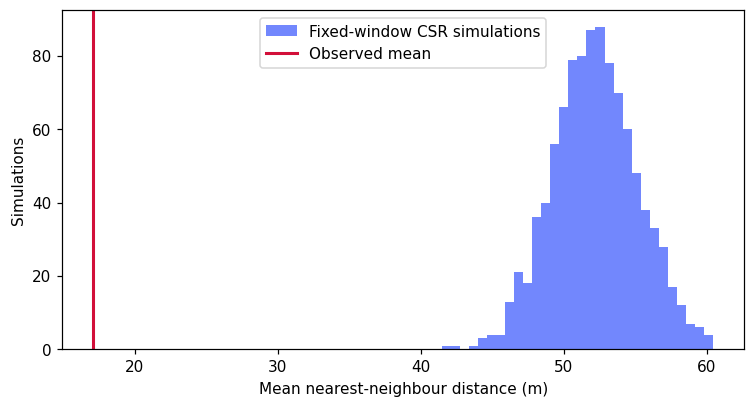

In [5]:
simulation_rng = np.random.default_rng(simulation_seed)
simulated = np.array([
    mean_nearest_distance(simulation_rng.uniform(lower, upper, size=(n, 2)))
    for _ in range(N_SIMULATIONS)
])


def monte_carlo_pvalue(observed, reference, alternative):
    reference = np.asarray(reference)
    p_less = (1 + np.count_nonzero(reference <= observed)) / (len(reference) + 1)
    p_greater = (1 + np.count_nonzero(reference >= observed)) / (len(reference) + 1)
    if alternative == "less":
        return float(p_less)
    if alternative == "greater":
        return float(p_greater)
    if alternative == "two-sided":
        # Explicit equal-tail convention, capped at one.
        return float(min(1.0, 2 * min(p_less, p_greater)))
    raise ValueError("Choose less, greater or two-sided.")


p_mc = monte_carlo_pvalue(observed, simulated, ALTERNATIVE)
print(f"Alternative: {ALTERNATIVE}; Monte Carlo p-value: {p_mc:.4f}")
print(f"Smallest one-sided p-value with this simulation count: {1/(N_SIMULATIONS+1):.4f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(simulated, bins=30, color="#7287fd", label="Fixed-window CSR simulations")
ax.axvline(observed, color="#d20f39", linewidth=2, label="Observed mean")
ax.set(xlabel="Mean nearest-neighbour distance (m)", ylabel="Simulations")
ax.legend()
plt.show()


The Monte Carlo calculation includes ties and the observed statistic in the finite-simulation correction. The two-sided option uses an explicitly stated equal-tail convention. Different conventions can yield different two-sided p-values.

A small lower-tail p-value is evidence of unusually short distances under this null. It does not identify a cause or locate individual clusters. A large p-value does not establish randomness. More simulations improve resolution, not necessarily significance.

## 5. Compare with the analytical approximation

Use $SE=0.26136\sqrt A/n$ and $z=(\bar D_O-\bar D_E)/SE$. This uncorrected planar approximation has a different boundary reference from the finite rectangle simulation. Disagreement deserves explanation; the two results are not required to match.

In [6]:
standard_error = 0.26136 * np.sqrt(area) / n
z = (observed - expected) / standard_error
if ALTERNATIVE == "less":
    p_analytical = norm.cdf(z)
elif ALTERNATIVE == "greater":
    p_analytical = norm.sf(z)
else:
    p_analytical = 2 * norm.sf(abs(z))
print(f"Analytical approximation: z={z:.3f}, p={p_analytical:.4g}")
print(f"Finite-window simulated mean: {simulated.mean():.3f} m")
print(f"Unbounded-plane theoretical mean: {expected:.3f} m")


Analytical approximation: z=-12.591, p=1.177e-36
Finite-window simulated mean: 52.185 m
Unbounded-plane theoretical mean: 50.000 m


## 6. Explore and explain

1. Run `clustered`, `csr` and `regular` with the same window and point count. Choose the test direction before running each investigation. Does the statistic match the visual pattern?
2. Keep the **current points** fixed and double the window area, extending it to the right. Predict the ratio before running the next cell. This changes the null model, not the observed distances.
3. Try another seed for the CSR pattern. A random process does not produce the same statistic every time.
4. Explain how repeated transactions at identical building coordinates could change the result.
5. Would uniform CSR be appropriate for accidents along a road network? State a more suitable geographical reference.

In [7]:
larger_window = (lower[0], lower[1], lower[0] + 2*(upper[0]-lower[0]), upper[1])
new_lower, new_upper = validate_window(larger_window)
new_area = float(np.prod(new_upper-new_lower))
new_expected = 0.5 / np.sqrt(n/new_area)
print(f"Original R={ratio:.3f}; doubled-area R={observed/new_expected:.3f}")
print("Observed distances are unchanged; the expected distance changes.")


Original R=0.342; doubled-area R=0.242
Observed distances are unchanged; the expected distance changes.


### Brief feedback

Doubling area increases the theoretical expected mean by a factor of √2 and reduces R by that factor. This is sensitivity to the reference window, not new evidence about the same fixed null. Coincident transaction records can shorten observed distances; aggregating them changes the event unit. A road-network question may require a network-constrained reference instead of uniform planar locations.

**Write a conclusion:** state the point unit, window, null model, alternative, observed mean, ratio, simulation count and p-value. Explain one limitation. Do not claim that the method proves a causal process.

Next: [Gordon Square worked example](../worked_examples/sec_04-A-Demonstration-point-pattern.md), [Ripley's K](../chapter_4/sec_04-04-Ripleys-K-Function.md), or [Week 5 slides](../part4.md).